# 5 - Modelo de análise de crédito: Gradient Boosting com e sem gênero (H2)

**Projeto final — SME0828 Introdução à Ciência de Dados**
Prof. Francisco A. Rodrigues — ICMC/USP

Grupo: _(nomes)_

<hr>

Agora construímos um **modelo de classificação** que prevê se um pedido de crédito será **negado** (classe 1) ou **aprovado** (classe 0), a partir das características do solicitante.

**Atenção:** o HMDA não informa se a pessoa pagou o empréstimo. Portanto, o modelo **não prevê inadimplência**. Ele aprende a **imitar a decisão dos bancos**.

Treinamos **dois** modelos, idênticos exceto por um detalhe:
- **com gênero**: recebe a variável `mulher`;
- **sem gênero**: não recebe a variável `mulher`.

**Hipótese H2:** mesmo **sem** a variável gênero, o modelo produz taxas de negação diferentes para homens e mulheres, porque outras variáveis carregam informação de gênero (*proxies*). Este notebook treina e avalia os modelos. As métricas de fairness ficam para a Etapa E (`06_fairness`).

### 1. Bibliotecas

In [1]:
import os
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# Define sementes aleatórias para reprodutibilidade.
SEMENTE = 42
random.seed(SEMENTE)
np.random.seed(SEMENTE)

# Paleta usada nos gráficos (a mesma das aulas).
BLUE   = "#2a78d6"   # homens / modelo
ORANGE = "#eb6834"   # mulheres
GRAY   = "#898781"   # referência

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)
os.makedirs("../figuras", exist_ok=True)
os.makedirs("../resultados", exist_ok=True)

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             roc_curve, precision_recall_curve, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)
import joblib

### 2. Leitura e preparação dos dados

Usamos a **base principal** (casos completos de renda, DTI e LTV), gerada no notebook `02_amostra`. Antes de ajustar os modelos, ainda precisamos tratar três pontos (registrados no `docs/protocolo.md`, seção 7):

1. **Renda menor ou igual a zero**: vamos usar o logaritmo da renda, que não existe para valores ≤ 0. Essas linhas são removidas.
2. **Outliers do LTV**: há valores impossíveis (até 29 milhões de %). Em vez de remover, **limitamos** o LTV aos percentis 0,1% e 99,9% (*winsorização*): valores acima do limite passam a valer o limite.
3. **Estado e idade faltantes**: removemos essas linhas para que a amostra seja a mesma da regressão logística (H1).

In [2]:
colunas = ["lei", "state_code", "income", "combined_loan_to_value_ratio",
           "loan_type", "dti", "applicant_age", "negado", "mulher"]

data = pd.read_parquet("../data/amostra_principal.parquet", columns=colunas)
print("Dimensão inicial:", data.shape)

# 1. Renda <= 0
print("Linhas com renda <= 0:", (data["income"] <= 0).sum())
data = data[data["income"] > 0]

# 2. Winsorização do LTV
limite_inf, limite_sup = data["combined_loan_to_value_ratio"].quantile([0.001, 0.999])
print(f"Limites do LTV: [{limite_inf:.2f}, {limite_sup:.2f}]")
data["ltv"] = data["combined_loan_to_value_ratio"].clip(limite_inf, limite_sup)

# Logaritmo da renda
data["log_renda"] = np.log(data["income"])

# 3. Estado e idade faltantes
data = data.dropna(subset=["state_code", "applicant_age"]).reset_index(drop=True)
print("Dimensão final:", data.shape)
data.head()

Dimensão inicial: (1547246, 9)
Linhas com renda <= 0: 7111
Limites do LTV: [13.99, 115.52]
Dimensão final: (1532885, 11)


,lei,state_code,income,combined_loan_to_value_ratio,loan_type,dti,applicant_age,negado,mulher,ltv,log_renda
0,549300QFJDBOCX7WKY08,TX,65.0,97.000,1,36%-<50%,25-34,0,0,97.000,4.174387
1,549300HW662MN1WU8550,CA,178.0,80.000,1,36%-<50%,35-44,0,1,80.000,5.181784
2,549300HW662MN1WU8550,CA,61.0,96.500,2,50%-60%,<25,0,0,96.500,4.110874
3,549300HW662MN1WU8550,MN,69.0,97.000,1,20%-<30%,25-34,0,1,97.000,4.234107
4,549300D36J5CQX0I4F44,MI,59.0,98.189,2,20%-<30%,<25,0,0,98.189,4.077537


### 3. Atributos

Os atributos de entrada são: log da renda, LTV, faixa de DTI, tipo de empréstimo, estado e faixa etária. Variáveis definidas **depois** da decisão (motivo da negação, taxa de juros etc.) **não** entram, pois revelariam a resposta ao modelo (*vazamento*).

O `HistGradientBoostingClassifier` aceita variáveis categóricas diretamente, sem one-hot encoding: basta que a coluna seja do tipo `category`.

In [3]:
categoricas = ["dti", "loan_type", "state_code", "applicant_age"]
for col in categoricas:
    data[col] = data[col].astype(str).astype("category")

atributos_sem_genero = ["log_renda", "ltv", "dti", "loan_type", "state_code", "applicant_age"]
atributos_com_genero = ["mulher"] + atributos_sem_genero

data[atributos_com_genero + ["negado"]].head()

,mulher,log_renda,ltv,dti,loan_type,state_code,applicant_age,negado
0,0,4.174387,97.000,36%-<50%,1,TX,25-34,0
1,1,5.181784,80.000,36%-<50%,1,CA,35-44,0
2,0,4.110874,96.500,50%-60%,2,CA,<25,0
3,1,4.234107,97.000,20%-<30%,1,MN,25-34,0
4,0,4.077537,98.189,20%-<30%,2,MI,<25,0


### 4. Divisão em treino e teste

Separamos **70% para treino** e **30% para teste**. A divisão é **estratificada** pelo alvo e pelo gênero ao mesmo tempo: as proporções de negados e de mulheres ficam iguais nos dois conjuntos. Os dois modelos usam **exatamente a mesma divisão**, para que a comparação seja justa.

In [4]:
estrato = data["negado"].astype(str) + "_" + data["mulher"].astype(str)

treino, teste = train_test_split(data, test_size=0.3, stratify=estrato, random_state=SEMENTE)

print("Treino:", treino.shape, f"- negados: {treino['negado'].mean():.1%} - mulheres: {treino['mulher'].mean():.1%}")
print("Teste: ", teste.shape, f"- negados: {teste['negado'].mean():.1%} - mulheres: {teste['mulher'].mean():.1%}")

y_treino = treino["negado"].values
y_teste = teste["negado"].values

Treino: (1073019, 11) - negados: 10.5% - mulheres: 38.9%
Teste:  (459866, 11) - negados: 10.5% - mulheres: 38.9%


### 5. Gradient Boosting e ajuste dos hiperparâmetros

O **Gradient Boosting** é um método de *ensemble* do tipo **boosting** (como o AdaBoost visto em aula): treina várias árvores de decisão **em sequência**, e cada nova árvore corrige os erros das anteriores. Usamos a versão `HistGradientBoostingClassifier`, muito mais rápida em bases grandes.

Para escolher os hiperparâmetros, usamos `GridSearchCV` com validação cruzada estratificada e `scoring='roc_auc'`, como nas aulas. Como a base de treino tem mais de 1 milhão de linhas, a busca é feita numa **amostra de 100 mil** pedidos do treino. Os hiperparâmetros escolhidos são usados nos dois modelos.

In [5]:
amostra_busca = treino.sample(n=100_000, random_state=SEMENTE)

param_grid = {
    "learning_rate": [0.05, 0.1],
    "max_leaf_nodes": [15, 31, 63],
}

busca = GridSearchCV(
    HistGradientBoostingClassifier(categorical_features="from_dtype", max_iter=300,
                                   early_stopping=True, random_state=SEMENTE),
    param_grid,
    scoring="roc_auc",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=SEMENTE),
)
busca.fit(amostra_busca[atributos_sem_genero], amostra_busca["negado"])

print("Melhores hiperparâmetros:", busca.best_params_)
print(f"AUC na validação cruzada: {busca.best_score_:.4f}")
pd.DataFrame(busca.cv_results_)[["params", "mean_test_score", "std_test_score"]].round(4)

Melhores hiperparâmetros: {'learning_rate': 0.05, 'max_leaf_nodes': 15}
AUC na validação cruzada: 0.7761


,params,mean_test_score,std_test_score
0,"{'learning_rate': 0.05, 'max_leaf_nodes': 15}",0.7761,0.0021
1,"{'learning_rate': 0.05, 'max_leaf_nodes': 31}",0.7758,0.0020
2,"{'learning_rate': 0.05, 'max_leaf_nodes': 63}",0.7733,0.0007
3,"{'learning_rate': 0.1, 'max_leaf_nodes': 15}",0.7753,0.0019
4,"{'learning_rate': 0.1, 'max_leaf_nodes': 31}",0.7747,0.0012
5,"{'learning_rate': 0.1, 'max_leaf_nodes': 63}",0.7721,0.0009


### 6. Escolha do limiar de decisão

O modelo devolve uma **probabilidade** de negação. Para transformá-la em classe (0 ou 1), precisamos de um **limiar**. O padrão é 0,5, mas, com classes desbalanceadas, ele faria o modelo prever pouquíssimas negações.

Seguindo o protocolo, escolhemos o limiar para que o modelo **negue a mesma proporção de pedidos que os bancos negaram** no treino. Para não usar o teste nessa escolha, as probabilidades vêm de uma **validação cruzada no treino** (`cross_val_predict`).

In [6]:
modelos = {}
limiares = {}

for nome, atributos in [("Com gênero", atributos_com_genero), ("Sem gênero", atributos_sem_genero)]:
    modelo = HistGradientBoostingClassifier(categorical_features="from_dtype", max_iter=300,
                                            early_stopping=True, random_state=SEMENTE,
                                            **busca.best_params_)

    proba_cv = cross_val_predict(modelo, treino[atributos], y_treino,
                                 cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE),
                                 method="predict_proba")[:, 1]
    limiares[nome] = np.quantile(proba_cv, 1 - y_treino.mean())

    modelos[nome] = modelo.fit(treino[atributos], y_treino)
    print(f"{nome}: limiar = {limiares[nome]:.4f}")

Com gênero: limiar = 0.1432


Sem gênero: limiar = 0.1433


### 7. Modelo de comparação: regressão logística

Para saber se o Gradient Boosting vale a pena, comparamos com um modelo mais simples: a **regressão logística** (sem gênero), com one-hot encoding nas categóricas e padronização (`StandardScaler`) nas numéricas, como na aula de regressão logística.

In [7]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

logistica = Pipeline([
    ("preparo", ColumnTransformer([
        ("num", StandardScaler(), ["log_renda", "ltv"]),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categoricas),
    ])),
    ("modelo", LogisticRegression(max_iter=1000)),
])
logistica.fit(treino[atributos_sem_genero], y_treino)
print("Regressão logística ajustada.")

Regressão logística ajustada.


### 8. Avaliação no conjunto de teste

Como as classes são desbalanceadas, **não usamos a acurácia** como métrica principal. Usamos:
- **AUC-ROC**: capacidade de separar negados de aprovados (0,5 = aleatório; 1 = perfeito);
- **PR-AUC** (*average precision*): mais informativa quando a classe positiva é rara;
- **Brier score**: erro quadrático médio das probabilidades (quanto menor, melhor).

In [8]:
probas = {
    "GB com gênero": modelos["Com gênero"].predict_proba(teste[atributos_com_genero])[:, 1],
    "GB sem gênero": modelos["Sem gênero"].predict_proba(teste[atributos_sem_genero])[:, 1],
    "Logística sem gênero": logistica.predict_proba(teste[atributos_sem_genero])[:, 1],
}

desempenho = pd.DataFrame({
    nome: {"AUC-ROC": roc_auc_score(y_teste, p),
           "PR-AUC": average_precision_score(y_teste, p),
           "Brier": brier_score_loss(y_teste, p)}
    for nome, p in probas.items()
}).T
desempenho.round(4)

,AUC-ROC,PR-AUC,Brier
GB com gênero,0.7868,0.5444,0.0649
GB sem gênero,0.7867,0.5444,0.0649
Logística sem gênero,0.7401,0.4723,0.0721


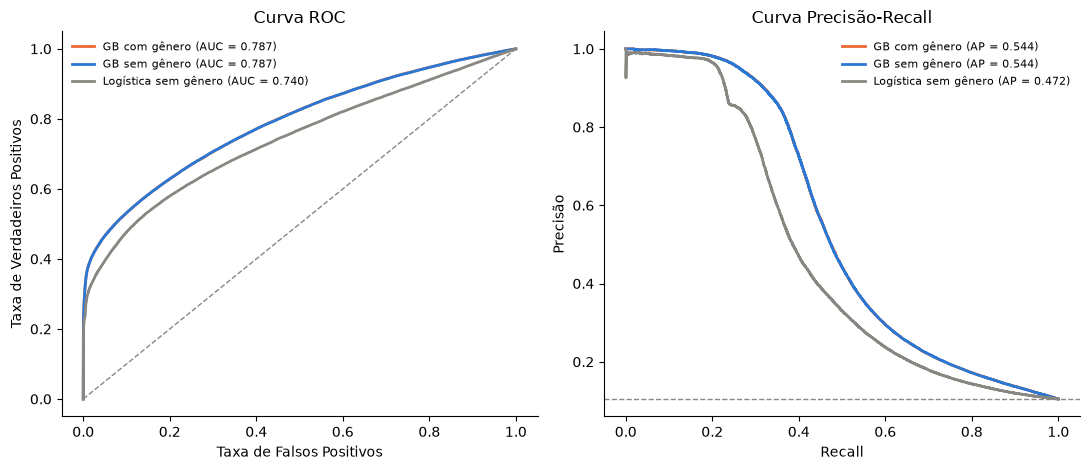

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
cores = {"GB com gênero": ORANGE, "GB sem gênero": BLUE, "Logística sem gênero": GRAY}

for nome, p in probas.items():
    fpr, tpr, _ = roc_curve(y_teste, p)
    axes[0].plot(fpr, tpr, color=cores[nome], linewidth=2, label=f"{nome} (AUC = {roc_auc_score(y_teste, p):.3f})")
    precisao, recall, _ = precision_recall_curve(y_teste, p)
    axes[1].plot(recall, precisao, color=cores[nome], linewidth=2, label=f"{nome} (AP = {average_precision_score(y_teste, p):.3f})")

axes[0].plot([0, 1], [0, 1], color=GRAY, linestyle="--", linewidth=1)
axes[0].set_xlabel("Taxa de Falsos Positivos")
axes[0].set_ylabel("Taxa de Verdadeiros Positivos")
axes[0].set_title("Curva ROC")
axes[1].axhline(y_teste.mean(), color=GRAY, linestyle="--", linewidth=1)
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precisão")
axes[1].set_title("Curva Precisão-Recall")
for ax in axes:
    ax.legend(frameon=False, fontsize=8)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.savefig("../figuras/h2_curvas_roc_pr.png", dpi=150)
plt.show()

As curvas dos dois Gradient Boosting praticamente se sobrepõem. Ou seja, **retirar a variável gênero quase não muda o desempenho**.

Agora aplicamos o limiar escolhido na seção 6 e olhamos a **matriz de confusão** e o relatório de classificação.

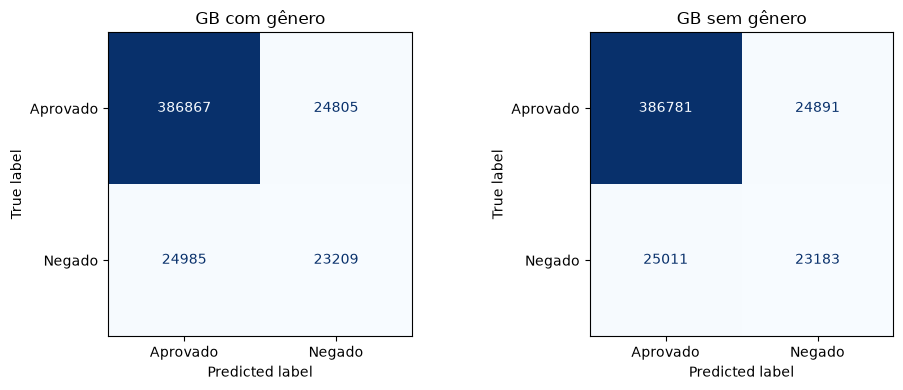

Gradient Boosting sem gênero:
              precision    recall  f1-score   support

    Aprovado       0.94      0.94      0.94    411672
      Negado       0.48      0.48      0.48     48194

    accuracy                           0.89    459866
   macro avg       0.71      0.71      0.71    459866
weighted avg       0.89      0.89      0.89    459866



In [10]:
pred_com = (probas["GB com gênero"] >= limiares["Com gênero"]).astype(int)
pred_sem = (probas["GB sem gênero"] >= limiares["Sem gênero"]).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, pred, nome in zip(axes, [pred_com, pred_sem], ["Com gênero", "Sem gênero"]):
    ConfusionMatrixDisplay(confusion_matrix(y_teste, pred), display_labels=["Aprovado", "Negado"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"GB {nome.lower()}")
plt.tight_layout()
plt.show()

print("Gradient Boosting sem gênero:")
print(classification_report(y_teste, pred_sem, target_names=["Aprovado", "Negado"]))

### 9. Prévia: taxa de negação prevista por gênero

A pergunta da H2 é se o modelo **sem gênero** ainda nega mais um grupo que o outro. Comparamos a taxa de negação **real** (decisão dos bancos) com a **prevista** por cada modelo, separada por gênero. A análise completa, com intervalos de confiança e outras métricas de fairness, é feita na Etapa E.

Diferença mulheres - homens (p.p.):
Real (bancos)    1.41
GB com gênero    3.43
GB sem gênero    3.66
dtype: float64


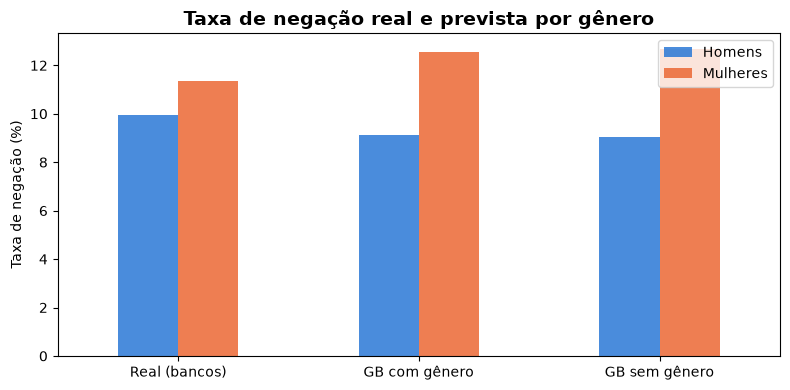

In [11]:
mulher = teste["mulher"].values == 1

taxas = pd.DataFrame({
    "Real (bancos)": [y_teste[~mulher].mean(), y_teste[mulher].mean()],
    "GB com gênero": [pred_com[~mulher].mean(), pred_com[mulher].mean()],
    "GB sem gênero": [pred_sem[~mulher].mean(), pred_sem[mulher].mean()],
}, index=["Homens", "Mulheres"])

print("Diferença mulheres - homens (p.p.):")
print((100 * (taxas.loc["Mulheres"] - taxas.loc["Homens"])).round(2))

(100 * taxas.T).plot(kind="bar", color=[BLUE, ORANGE], alpha=0.85, rot=0, figsize=(8, 4))
plt.ylabel("Taxa de negação (%)")
plt.title("Taxa de negação real e prevista por gênero", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("../figuras/h2_taxa_prevista_genero.png", dpi=150)
plt.show()

### 10. Salvando os resultados

Salvamos a tabela de desempenho e as previsões no teste. As previsões e os modelos são usados nas Etapas E (fairness) e F (proxies) e ficam na pasta `resultados/` local (não vão para o GitHub, por serem arquivos grandes).

In [12]:
with open("../resultados/h2_performance.md", "w", encoding="utf-8") as f:
    f.write(desempenho.round(4).to_markdown())
    f.write(f"\n\nTeste: 30% da base ({len(teste):,} pedidos). Hiperparâmetros (GridSearchCV): {busca.best_params_}. "
            f"Limiares: com gênero = {limiares['Com gênero']:.4f}, sem gênero = {limiares['Sem gênero']:.4f}.\n")

previsoes = teste[["negado", "mulher", "dti", "ltv", "log_renda", "loan_type", "state_code", "applicant_age"]].copy()
previsoes["proba_com_genero"] = probas["GB com gênero"]
previsoes["proba_sem_genero"] = probas["GB sem gênero"]
previsoes["pred_com_genero"] = pred_com
previsoes["pred_sem_genero"] = pred_sem
previsoes.to_parquet("../resultados/h2_previsoes_teste.parquet", index=False)

joblib.dump({"modelos": modelos, "limiares": limiares,
             "atributos": {"Com gênero": atributos_com_genero, "Sem gênero": atributos_sem_genero}},
            "../resultados/h2_modelos.joblib")
print("Arquivos salvos em ../resultados/")

Arquivos salvos em ../resultados/


### Conclusão

- O Gradient Boosting atinge **AUC = 0,787** e **PR-AUC = 0,544** no teste, bem acima da regressão logística (AUC = 0,740; PR-AUC = 0,472). Os hiperparâmetros escolhidos pelo `GridSearchCV` foram `learning_rate = 0.05` e `max_leaf_nodes = 15`.
- **Retirar a variável gênero não muda o desempenho**: AUC de 0,7868 com gênero contra 0,7867 sem gênero. O gênero praticamente não acrescenta informação ao modelo.
- Mesmo assim, o modelo **sem gênero** prevê **3,7 p.p. mais negações para mulheres** do que para homens. Isso é **mais que o dobro** da diferença real nas decisões dos bancos (1,4 p.p.).
- Ou seja, o modelo **amplia** a diferença entre gêneros sem nunca ter visto a variável `mulher`. Isso é um indício de que outras variáveis (renda, DTI, idade, estado...) carregam informação de gênero (*proxies*), como prevê a **H2**.
- Isso contrasta com a Etapa B: a regressão logística mostrou que, **para perfis iguais**, os bancos não tratam homens e mulheres de forma diferente. Uma explicação possível, a ser verificada na Etapa E, é o **limiar único**: se as mulheres da amostra têm, em média, perfis de risco um pouco mais altos, mais delas ficam logo acima do limiar, e a diferença nas decisões fica maior que a diferença nas probabilidades.
- As próximas etapas medem isso formalmente: **Etapa E** (métricas de fairness com intervalos de confiança) e **Etapa F** (quais variáveis funcionam como proxy do gênero).